# Earthkit and a server-to-browser export boundary

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/25-earthkit-export.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/25-earthkit-export.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `fe8f8c995dfd63610ec1c4f22b8134943165948a75351064435dd42999fc222e`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Earthkit and a server-to-browser export boundary

**Lesson 25 · Original synthetic data · Independent educational project**

## Objectives

Design a small, explicit export contract; validate units and provenance after serialization.

[Previous](24-polytope.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/25-earthkit-export.ipynb) · [Next](26-data-lake.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=25-earthkit-export.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

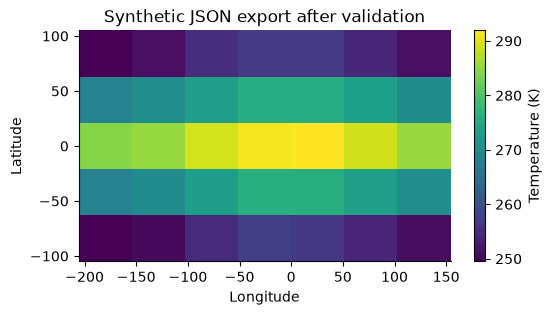

Small transfer size: 1104 bytes


In [2]:
import json
cube = lab.synthetic_cube(nlat=5, nlon=7)
export = {"schema_version": 1, "variable": "temperature", "units": "K",
          "lat": cube["lat"].tolist(), "lon": cube["lon"].tolist(), "values": cube["temperature"][0].tolist(),
          "provenance": {"source": "original synthetic generator", "license": "CC BY 4.0",
                         "retrieved": "2026-11-15", "method": "selected day zero; native K retained"}}
wire = json.dumps(export, allow_nan=False)
validated = lab.validate_export(json.loads(wire))
assert np.array_equal(validated["values"], cube["temperature"][0])
assert len(wire.encode()) < 10000
fig, ax = plt.subplots(figsize=(6, 3))
im = ax.pcolormesh(validated["lon"], validated["lat"], validated["values"], shading="auto")
fig.colorbar(im, ax=ax, label="Temperature (K)")
ax.set(title="Synthetic JSON export after validation", xlabel="Longitude", ylabel="Latitude")
plt.show()
print("Small transfer size:", len(wire.encode()), "bytes")

## Exercise

Add an explicit K-to-°C conversion and record it in metadata, then observe that the narrow schema rejects °C until you intentionally update the contract.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

Earthkit provides Python tools for Earth-system data, including GRIB-oriented workflows through associated native capabilities. Run authentic decoding and authorized retrieval on a suitable server or local environment, then export a small permitted subset. No Earthkit/GRIB decoding, authentication or official download runs in this browser exercise.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://earthkit-data.readthedocs.io/en/latest/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).